# Agent 2: Diagnosis Agent — HAM10000 Skin Lesion Classification

**Event**: Jaypee Agentic AI International Summit 2026 | Track 2: Healthcare
**Task**: Classify dermoscopic images into 7 skin-lesion classes; produce class probabilities for the triage pipeline.

### Models trained (one at a time, all checkpoints saved separately)
| # | Model | timm name | Params |
|---|---|---|---|
| 1 | EfficientNet-B0 | efficientnet_b0 | ~4M |
| 2 | EfficientNet-B3 | efficientnet_b3 | ~12M |
| 3 | ResNet-50 | resnet50 | ~25M |
| 4 | ViT-Small/16 | vit_small_patch16_224 | ~22M |

**Final step**: 4-model TTA ensemble → DiagnosisAgent inference API

**Dataset path:** `Path("/content/health-training/Health/training")`

---

## 0. Mount Google Drive & Extract Dataset

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import zipfile, os
zip_file_path  = '/content/drive/MyDrive/health-training.zip'
extract_to_dir = '/content/health-training'
os.makedirs(extract_to_dir, exist_ok=True)
if not os.path.exists('/content/health-training/Health/training'):
    try:
        with zipfile.ZipFile(zip_file_path, "r") as z:
            z.extractall(extract_to_dir)
        print(f"Extracted to {extract_to_dir}")
    except FileNotFoundError:
        print("Error: zip not found. Mount Drive first.")
    except zipfile.BadZipFile:
        print("Error: corrupted zip.")
else:
    print("Dataset already extracted. Skipping.")

Dataset already extracted. Skipping.


---
## 1. Install Missing Packages

In [3]:
import subprocess, sys
def pip_install(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])
TO_INSTALL = []
for pkg, imp in [("timm","timm"),("scikit-learn","sklearn"),("matplotlib","matplotlib"),
                 ("seaborn","seaborn"),("tqdm","tqdm"),("pandas","pandas"),
                 ("pillow","PIL"),("numpy","numpy")]:
    try: __import__(imp)
    except ImportError: TO_INSTALL.append(pkg)
if TO_INSTALL:
    print(f"Installing: {TO_INSTALL}")
    pip_install(*TO_INSTALL)
else:
    print("All packages already installed.")

All packages already installed.


---
## 2. Imports & Reproducibility

In [4]:
import os, random, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    f1_score, recall_score, confusion_matrix, classification_report)
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch  : {torch.__version__}")
print(f"timm   : {timm.__version__}")
print(f"PIL    : {Image.__version__}")
print(f"Device : {DEVICE}")
if DEVICE.type == "cuda": print(f"GPU    : {torch.cuda.get_device_name(0)}")

torch  : 2.11.0+cu130
timm   : 1.0.30
PIL    : 11.3.0
Device : cuda
GPU    : Tesla T4


---
## 3. Paths & Hyper-parameters

In [5]:
BASE_DIR       = Path('/content/health-training/Health/training')
IMAGE_DIR      = BASE_DIR / 'images'
METADATA_CSV   = BASE_DIR / 'metadata.csv'
CACHE_DIR      = Path('/content/cache_shades_of_gray')
CHECKPOINT_DIR = Path('/content/checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

print(f"BASE_DIR  : {BASE_DIR.resolve()} (exists: {BASE_DIR.exists()})")
print(f"METADATA  : {METADATA_CSV} (exists: {METADATA_CSV.exists()})")
if not BASE_DIR.exists():
    raise FileNotFoundError(f"Dataset not found at {BASE_DIR}. Run extraction cell first.")

IMG_SIZE     = 224
BATCH_SIZE   = 32
NUM_EPOCHS   = 12
LR           = 3e-4
LABEL_SMOOTH = 0.05
VAL_SPLIT    = 0.2
NUM_WORKERS  = 2
PIN_MEMORY   = (DEVICE.type == "cuda")

LABEL_MAP    = {"nv":0,"mel":1,"bkl":2,"bcc":3,"akiec":4,"vasc":5,"df":6}
IDX_TO_CLASS = {v:k for k,v in LABEL_MAP.items()}
CLASS_NAMES  = [IDX_TO_CLASS[i] for i in range(7)]
NUM_CLASSES  = len(LABEL_MAP)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ── Model registry — all 4 models to train ───────────────────────────────
MODEL_REGISTRY = {
    "efficientnet_b0" : {"timm_name": "efficientnet_b0",       "ckpt": "best_efficientnet_b0.pth"},
    "efficientnet_b3" : {"timm_name": "efficientnet_b3",       "ckpt": "best_efficientnet_b3.pth"},
    "resnet50"        : {"timm_name": "resnet50",              "ckpt": "best_resnet50.pth"},
    "vit_small"       : {"timm_name": "vit_small_patch16_224", "ckpt": "best_vit_small.pth"},
}
print(f"Config ready. Classes: {CLASS_NAMES}")
print(f"Models to train: {list(MODEL_REGISTRY.keys())}")

BASE_DIR  : /content/health-training/Health/training (exists: True)
METADATA  : /content/health-training/Health/training/metadata.csv (exists: True)
Config ready. Classes: ['nv', 'mel', 'bkl', 'bcc', 'akiec', 'vasc', 'df']
Models to train: ['efficientnet_b0', 'efficientnet_b3', 'resnet50', 'vit_small']


---
## 4. Load & Inspect Metadata

In [6]:
df = pd.read_csv(METADATA_CSV)
print(f"Total rows: {len(df)}")
print(f"Columns: {df.columns.tolist()}")
display(df.head(3))

Total rows: 7762
Columns: ['image_id', 'lesion_id', 'dx', 'age', 'sex', 'localization']


,image_id,lesion_id,dx,age,sex,localization
0,ISIC_0027419,HAM_0000118,bkl,80.0,male,scalp
1,ISIC_0025030,HAM_0000118,bkl,80.0,male,scalp
2,ISIC_0031633,HAM_0001466,bkl,75.0,male,ear


All dx values mapped OK.

Class distribution:
dx
nv       5212
mel       856
bkl       848
bcc       400
akiec     249
vasc      109
df         88


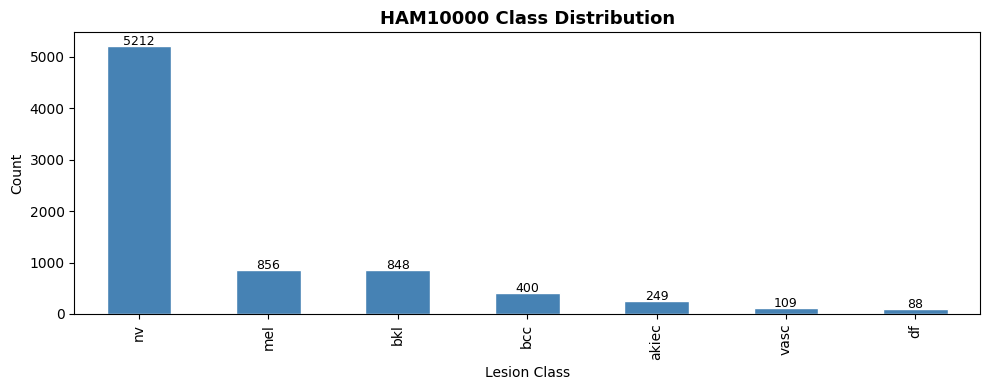

In [7]:
df["label"] = df["dx"].map(LABEL_MAP)
unmapped = df[df["label"].isna()]
if len(unmapped) > 0:
    print(f"WARNING: {len(unmapped)} unknown dx values: {unmapped['dx'].unique()}")
else:
    print("All dx values mapped OK.")
df = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)

dist = df["dx"].value_counts()
print("\nClass distribution:"); print(dist.to_string())
fig, ax = plt.subplots(figsize=(10,4))
dist.plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
ax.set_title("HAM10000 Class Distribution", fontsize=13, fontweight="bold")
ax.set_xlabel("Lesion Class"); ax.set_ylabel("Count")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()+20), ha="center", fontsize=9)
plt.tight_layout(); plt.savefig("/content/class_distribution.png", dpi=150); plt.show()

---
## 5. Leakage Check & Lesion-ID Split

In [8]:
print("Computing MD5 hashes for duplicate detection...")
hashes, duplicates = {}, []
for img_id in tqdm(df["image_id"], desc="Hashing"):
    for ext in [".jpg",".jpeg",".png"]:
        fp = IMAGE_DIR / f"{img_id}{ext}"
        if fp.exists():
            md5 = hashlib.md5(fp.read_bytes()).hexdigest()
            if md5 in hashes: duplicates.append((img_id, hashes[md5]))
            else: hashes[md5] = img_id
            break
print(f"Duplicate pairs found: {len(duplicates)}")
if duplicates: print("Sample:", duplicates[:5])

Computing MD5 hashes for duplicate detection...


Hashing:   0%|          | 0/7762 [00:00<?, ?it/s]

Duplicate pairs found: 2
Sample: [('ISIC_0024366', 'ISIC_0029861'), ('ISIC_0024777', 'ISIC_0029938')]


In [9]:
unique_lesions = df[["lesion_id","label"]].drop_duplicates("lesion_id")
train_lesions, val_lesions = train_test_split(
    unique_lesions["lesion_id"].tolist(), test_size=VAL_SPLIT,
    random_state=SEED, stratify=unique_lesions["label"].tolist())
train_df = df[df["lesion_id"].isin(train_lesions)].reset_index(drop=True)
val_df   = df[df["lesion_id"].isin(val_lesions)].reset_index(drop=True)
overlap  = set(train_df["lesion_id"]) & set(val_df["lesion_id"])
assert len(overlap) == 0, f"LEAKAGE: {overlap}"
print("✅ No lesion_id leakage.")
print(f"Train: {len(train_df)} images | Val: {len(val_df)} images")
print(f"\nTrain dist:\n{train_df['dx'].value_counts().to_string()}")
print(f"\nVal dist:\n{val_df['dx'].value_counts().to_string()}")

✅ No lesion_id leakage.
Train: 6209 images | Val: 1553 images

Train dist:
dx
nv       4172
mel       684
bkl       679
bcc       319
akiec     197
vasc       88
df         70

Val dist:
dx
nv       1040
mel       172
bkl       169
bcc        81
akiec      52
vasc       21
df         18


---
## 6. Preprocessing — Shades of Gray Colour Constancy

Applied **once** and cached to disk. All 4 models share the same cached images.

⚠️  Running preprocessing...


Preprocessing & caching:   0%|          | 0/6209 [00:00<?, ?it/s]

⚠️  Running preprocessing...


Preprocessing & caching:   0%|          | 0/1553 [00:00<?, ?it/s]

Train: 6209 | Val: 1553


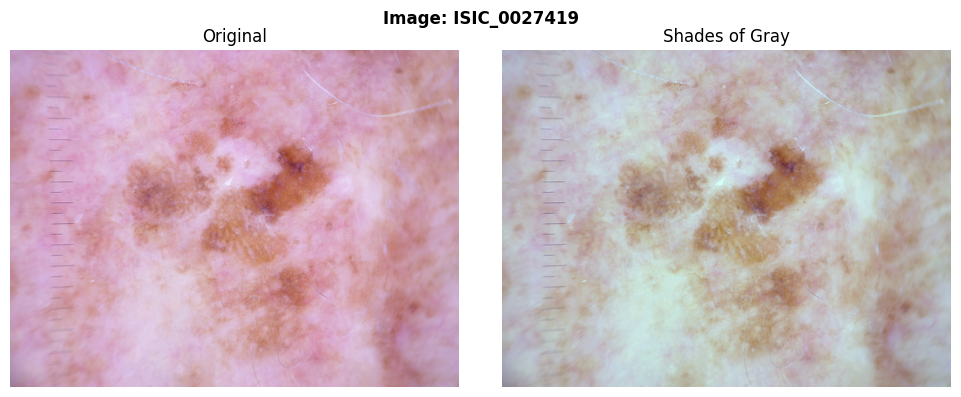

In [10]:
def shades_of_gray(img_np, power=6):
    img  = img_np.astype(np.float32)
    norm = np.power(np.mean(np.power(img, power), axis=(0,1)), 1.0/power)
    norm = norm / (norm.mean() + 1e-8)
    return np.clip(img / (norm + 1e-8), 0, 255).astype(np.uint8)

def find_image_path(image_id, image_dir):
    for ext in [".jpg",".jpeg",".png",".JPG",".JPEG",".PNG"]:
        fp = image_dir / f"{image_id}{ext}"
        if fp.exists(): return fp
    return None

RESAMPLE = Image.Resampling.BILINEAR

def preprocess_and_cache(df, image_dir, cache_dir, img_size=224):
    cache_dir.mkdir(parents=True, exist_ok=True)
    paths, missing = [], 0
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Preprocessing & caching"):
        img_id = row["image_id"]; out_fp = cache_dir / f"{img_id}.jpg"
        if out_fp.exists(): paths.append(str(out_fp)); continue
        src = find_image_path(img_id, image_dir)
        if src is None: missing += 1; paths.append(None); continue
        img_np = np.array(Image.open(src).convert("RGB"))
        img    = Image.fromarray(shades_of_gray(img_np)).resize((img_size, img_size), RESAMPLE)
        img.save(out_fp, quality=95); paths.append(str(out_fp))
    if missing: print(f"⚠️  {missing} images not found.")
    df = df.copy(); df["cache_path"] = paths
    return df

def ensure_cache(df, image_dir, cache_dir, img_size):
    if "cache_path" not in df.columns or df["cache_path"].isna().any():
        print("⚠️  Running preprocessing...")
        df = preprocess_and_cache(df.copy(), image_dir, cache_dir, img_size)
        df = df.dropna(subset=["cache_path"])
    return df.reset_index(drop=True)

train_df = ensure_cache(train_df, IMAGE_DIR, CACHE_DIR, IMG_SIZE)
val_df   = ensure_cache(val_df,   IMAGE_DIR, CACHE_DIR, IMG_SIZE)
print(f"Train: {len(train_df)} | Val: {len(val_df)}")

# Visual check
sample_id  = train_df["image_id"].iloc[0]
sample_src = find_image_path(sample_id, IMAGE_DIR)
if sample_src:
    orig_np = np.array(Image.open(sample_src).convert("RGB"))
    sog_np  = shades_of_gray(orig_np)
    fig, axes = plt.subplots(1,2,figsize=(10,4))
    axes[0].imshow(orig_np); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(sog_np);  axes[1].set_title("Shades of Gray"); axes[1].axis("off")
    plt.suptitle(f"Image: {sample_id}", fontweight="bold")
    plt.tight_layout(); plt.savefig("/content/shades_of_gray_example.png", dpi=150); plt.show()

---
## 7. Dataset, Transforms & DataLoaders

In [11]:
class HAMDataset(Dataset):
    def __init__(self, df, transform=None):
        self.paths  = [str(p) for p in df["cache_path"].tolist()]
        self.labels = [int(l) for l in df["label"].tolist()]
        self.transform = transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform: img = self.transform(img)
        return img, self.labels[idx]

train_transform = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.8,1.0)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomRotation(degrees=360),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    T.ToTensor(), T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
val_transform = T.Compose([
    T.Resize((IMG_SIZE,IMG_SIZE)),
    T.ToTensor(), T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
tta_transforms = [
    T.Compose([T.Resize((IMG_SIZE,IMG_SIZE)), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize((IMG_SIZE,IMG_SIZE)), T.RandomHorizontalFlip(p=1.0), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize((IMG_SIZE,IMG_SIZE)), T.RandomVerticalFlip(p=1.0), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize((IMG_SIZE,IMG_SIZE)), T.RandomHorizontalFlip(p=1.0), T.RandomVerticalFlip(p=1.0), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
]

train_loader = DataLoader(HAMDataset(train_df, transform=train_transform),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader   = DataLoader(HAMDataset(val_df, transform=val_transform),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

imgs, labels = next(iter(train_loader))
print(f"✅ DataLoader OK — batch shape: {imgs.shape}, labels: {labels[:5].tolist()}")
print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")

✅ DataLoader OK — batch shape: torch.Size([32, 3, 224, 224]), labels: [6, 2, 2, 0, 3]
Train batches: 195 | Val batches: 49


---
## 8. Square-Root Class Weights & Shared Training Utilities

In [12]:
# ── Class weights ────────────────────────────────────────────────────────────
def compute_sqrt_class_weights(df, num_classes):
    counts  = np.array([len(df[df["label"]==c]) for c in range(num_classes)], dtype=np.float32)
    weights = np.sqrt(counts.sum() / (counts + 1e-8))
    weights = weights / weights.sum() * num_classes
    print("Class weights (sqrt):")
    for i, (cls, w) in enumerate(zip(CLASS_NAMES, weights)):
        print(f"  {cls:6s}  [{counts[i]:5.0f} samples]  weight = {w:.4f}")
    return torch.tensor(weights, dtype=torch.float32).to(DEVICE)

class_weights = compute_sqrt_class_weights(train_df, NUM_CLASSES)

# ── Shared training functions ─────────────────────────────────────────────────
def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, device=DEVICE):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    total_loss = 0.0; all_preds, all_targets = [], []
    if is_train:
        for imgs, labels in tqdm(loader, leave=False, desc="train"):
            imgs, labels = imgs.to(device), labels.to(device)
            logits = model(imgs); loss = criterion(logits, labels)
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            if scheduler: scheduler.step()
            total_loss += loss.item() * imgs.size(0)
            all_preds.extend(logits.argmax(dim=1).cpu().numpy())
            all_targets.extend(labels.cpu().numpy())
    else:
        with torch.no_grad():
            for imgs, labels in tqdm(loader, leave=False, desc="val"):
                imgs, labels = imgs.to(device), labels.to(device)
                logits = model(imgs); loss = criterion(logits, labels)
                total_loss += loss.item() * imgs.size(0)
                all_preds.extend(logits.argmax(dim=1).cpu().numpy())
                all_targets.extend(labels.cpu().numpy())
    return total_loss/len(loader.dataset), np.array(all_preds), np.array(all_targets)

def compute_metrics(preds, targets):
    return {
        "acc":        accuracy_score(targets, preds),
        "bal_acc":    balanced_accuracy_score(targets, preds),
        "macro_f1":   f1_score(targets, preds, average="macro", zero_division=0),
        "mel_recall": recall_score(targets, preds, labels=[LABEL_MAP["mel"]], average="macro", zero_division=0),
    }

def train_model(timm_name, ckpt_name, num_epochs=NUM_EPOCHS):
    """
    Full training loop for any timm model.
    Returns: (model, history, best_epoch, best_bal_acc)
    """
    print("\n" + "=" * 65)
    print(f"  Training: {timm_name}  |  {num_epochs} epochs")
    print("=" * 65)
    model = timm.create_model(timm_name, pretrained=True, num_classes=NUM_CLASSES).to(DEVICE)
    print(f"  Parameters: {sum(p.numel() for p in model.parameters()):,}")

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTH)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=LR, steps_per_epoch=len(train_loader),
        epochs=num_epochs, pct_start=0.3, div_factor=25, final_div_factor=1e4)

    best_bal_acc, best_epoch, history = 0.0, 0, []
    ckpt_path = CHECKPOINT_DIR / ckpt_name

    header = f"{'Epoch':>5} | {'TrLoss':>7} | {'VLoss':>7} | {'Acc':>6} | {'BalAcc':>7} | {'MacroF1':>8} | {'MelRec':>7}"
    print(header); print("-" * len(header))

    for epoch in range(1, num_epochs + 1):
        print(f"\nEpoch {epoch}/{num_epochs}", flush=True)
        tr_loss, _, _              = run_epoch(model, train_loader, criterion, optimizer=optimizer, scheduler=scheduler)
        val_loss, val_preds, val_t = run_epoch(model, val_loader, criterion)
        m = compute_metrics(val_preds, val_t)
        history.append({"epoch":epoch, "tr_loss":tr_loss, "val_loss":val_loss, **m})
        tag = ""
        if m["bal_acc"] > best_bal_acc:
            best_bal_acc = m["bal_acc"]; best_epoch = epoch
            torch.save(model.state_dict(), ckpt_path); tag = "  ← BEST"
        print(f"{epoch:>5} | {tr_loss:>7.4f} | {val_loss:>7.4f} | {m['acc']:>6.4f} | {m['bal_acc']:>7.4f} | {m['macro_f1']:>8.4f} | {m['mel_recall']:>7.4f}{tag}", flush=True)

    print(f"\n✅ Done: {timm_name}  Best epoch: {best_epoch}  BalAcc: {best_bal_acc:.4f}")
    print(f"   Checkpoint saved: {ckpt_path}")
    return model, history, best_epoch, best_bal_acc

print("✅ Shared utilities ready.")

Class weights (sqrt):
  nv      [ 4172 samples]  weight = 0.2433
  mel     [  684 samples]  weight = 0.6009
  bkl     [  679 samples]  weight = 0.6031
  bcc     [  319 samples]  weight = 0.8798
  akiec   [  197 samples]  weight = 1.1196
  vasc    [   88 samples]  weight = 1.6752
  df      [   70 samples]  weight = 1.8782
✅ Shared utilities ready.


---
## 9. Train Model 1 — EfficientNet-B0

Lightweight & fast (~4M params). Good baseline for dermatology.

In [13]:
efnb0_model, efnb0_history, efnb0_best_epoch, efnb0_best_bal = train_model(
    timm_name="efficientnet_b0",
    ckpt_name="best_efficientnet_b0.pth"
)


  Training: efficientnet_b0  |  12 epochs


  Parameters: 4,016,515
Epoch |  TrLoss |   VLoss |    Acc |  BalAcc |  MacroF1 |  MelRec
-----------------------------------------------------------------

Epoch 1/12


train:   0%|          | 0/195 [00:00<?, ?it/s]

val:   0%|          | 0/49 [00:00<?, ?it/s]

    1 |  3.0432 |  2.3095 | 0.4552 |  0.2804 |   0.2357 |  0.2442  ← BEST

Epoch 2/12


train:   0%|          | 0/195 [00:00<?, ?it/s]

... (35 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

val:   0%|          | 0/49 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

   12 |  0.6984 |  1.1531 | 0.8255 |  0.6817 |   0.6941 |  0.5698

✅ Done: efficientnet_b0  Best epoch: 6  BalAcc: 0.7074
   Checkpoint saved: /content/checkpoints/best_efficientnet_b0.pth


In [15]:
import os
os.makedirs('/content/drive/MyDrive/dermaguard_checkpoints', exist_ok=True)

!cp /content/checkpoints/best_efficientnet_b0.pth /content/drive/MyDrive/dermaguard_checkpoints/
print("✅ EfficientNet-B0 safely backed up to Google Drive!")

✅ EfficientNet-B0 safely backed up to Google Drive!


---
## 10. Train Model 2 — EfficientNet-B3

Larger EfficientNet variant (~12M params). Better accuracy than B0.

In [16]:
efnb3_model, efnb3_history, efnb3_best_epoch, efnb3_best_bal = train_model(
    timm_name="efficientnet_b3",
    ckpt_name="best_efficientnet_b3.pth"
)


  Training: efficientnet_b3  |  12 epochs
  Parameters: 10,706,991
Epoch |  TrLoss |   VLoss |    Acc |  BalAcc |  MacroF1 |  MelRec
-----------------------------------------------------------------

Epoch 1/12


train:   0%|          | 0/195 [00:00<?, ?it/s]

val:   0%|          | 0/49 [00:00<?, ?it/s]

    1 |  2.9555 |  2.1037 | 0.5010 |  0.3258 |   0.2599 |  0.3779  ← BEST

Epoch 2/12


train:   0%|          | 0/195 [00:00<?, ?it/s]

val:   0%|          | 0/49 [00:00<?, ?it/s]

... (33 outputs left out)

train:   0%|          | 0/195 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

val:   0%|          | 0/49 [00:00<?, ?it/s]

   12 |  0.6481 |  1.1466 | 0.8390 |  0.7134 |   0.7152 |  0.6221

✅ Done: efficientnet_b3  Best epoch: 9  BalAcc: 0.7375
   Checkpoint saved: /content/checkpoints/best_efficientnet_b3.pth


In [17]:
!cp /content/checkpoints/best_efficientnet_b3.pth /content/drive/MyDrive/dermaguard_checkpoints/
print("✅ EfficientNet-B3 safely backed up to Google Drive!")


✅ EfficientNet-B3 safely backed up to Google Drive!


---
## 11. Train Model 3 — ResNet-50

Classic CNN backbone (~25M params). Well-studied, different inductive bias from EfficientNet.

In [18]:
resnet_model, resnet_history, resnet_best_epoch, resnet_best_bal = train_model(
    timm_name="resnet50",
    ckpt_name="best_resnet50.pth"
)


  Training: resnet50  |  12 epochs


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

  Parameters: 23,522,375
Epoch |  TrLoss |   VLoss |    Acc |  BalAcc |  MacroF1 |  MelRec
-----------------------------------------------------------------

Epoch 1/12


train:   0%|          | 0/195 [00:00<?, ?it/s]

val:   0%|          | 0/49 [00:00<?, ?it/s]

... (35 outputs left out)

train:   0%|          | 0/195 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

val:   0%|          | 0/49 [00:00<?, ?it/s]

   12 |  0.9084 |  1.1252 | 0.8210 |  0.7174 |   0.7012 |  0.5174

✅ Done: resnet50  Best epoch: 9  BalAcc: 0.7355
   Checkpoint saved: /content/checkpoints/best_resnet50.pth


In [19]:
!cp /content/checkpoints/best_resnet50.pth /content/drive/MyDrive/dermaguard_checkpoints/
print("✅ ResNet-50 safely backed up to Google Drive!")


✅ ResNet-50 safely backed up to Google Drive!


---
## 12. Train Model 4 — ViT-Small/16

Vision Transformer (~22M params). Captures global context — complementary to CNNs.

In [20]:
vit_model, vit_history, vit_best_epoch, vit_best_bal = train_model(
    timm_name="vit_small_patch16_224",
    ckpt_name="best_vit_small.pth"
)


  Training: vit_small_patch16_224  |  12 epochs


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

  Parameters: 21,668,359
Epoch |  TrLoss |   VLoss |    Acc |  BalAcc |  MacroF1 |  MelRec
-----------------------------------------------------------------

Epoch 1/12


train:   0%|          | 0/195 [00:00<?, ?it/s]

val:   0%|          | 0/49 [00:00<?, ?it/s]

... (41 outputs left out)

train:   0%|          | 0/195 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

val:   0%|          | 0/49 [00:00<?, ?it/s]

   12 |  0.7792 |  1.1260 | 0.8094 |  0.7079 |   0.7092 |  0.5407

✅ Done: vit_small_patch16_224  Best epoch: 9  BalAcc: 0.7165
   Checkpoint saved: /content/checkpoints/best_vit_small.pth


In [21]:
!cp /content/checkpoints/best_vit_small.pth /content/drive/MyDrive/dermaguard_checkpoints/
print("✅ ViT-Small safely backed up to Google Drive!")


✅ ViT-Small safely backed up to Google Drive!


---
## 13. Training Curves — All 4 Models

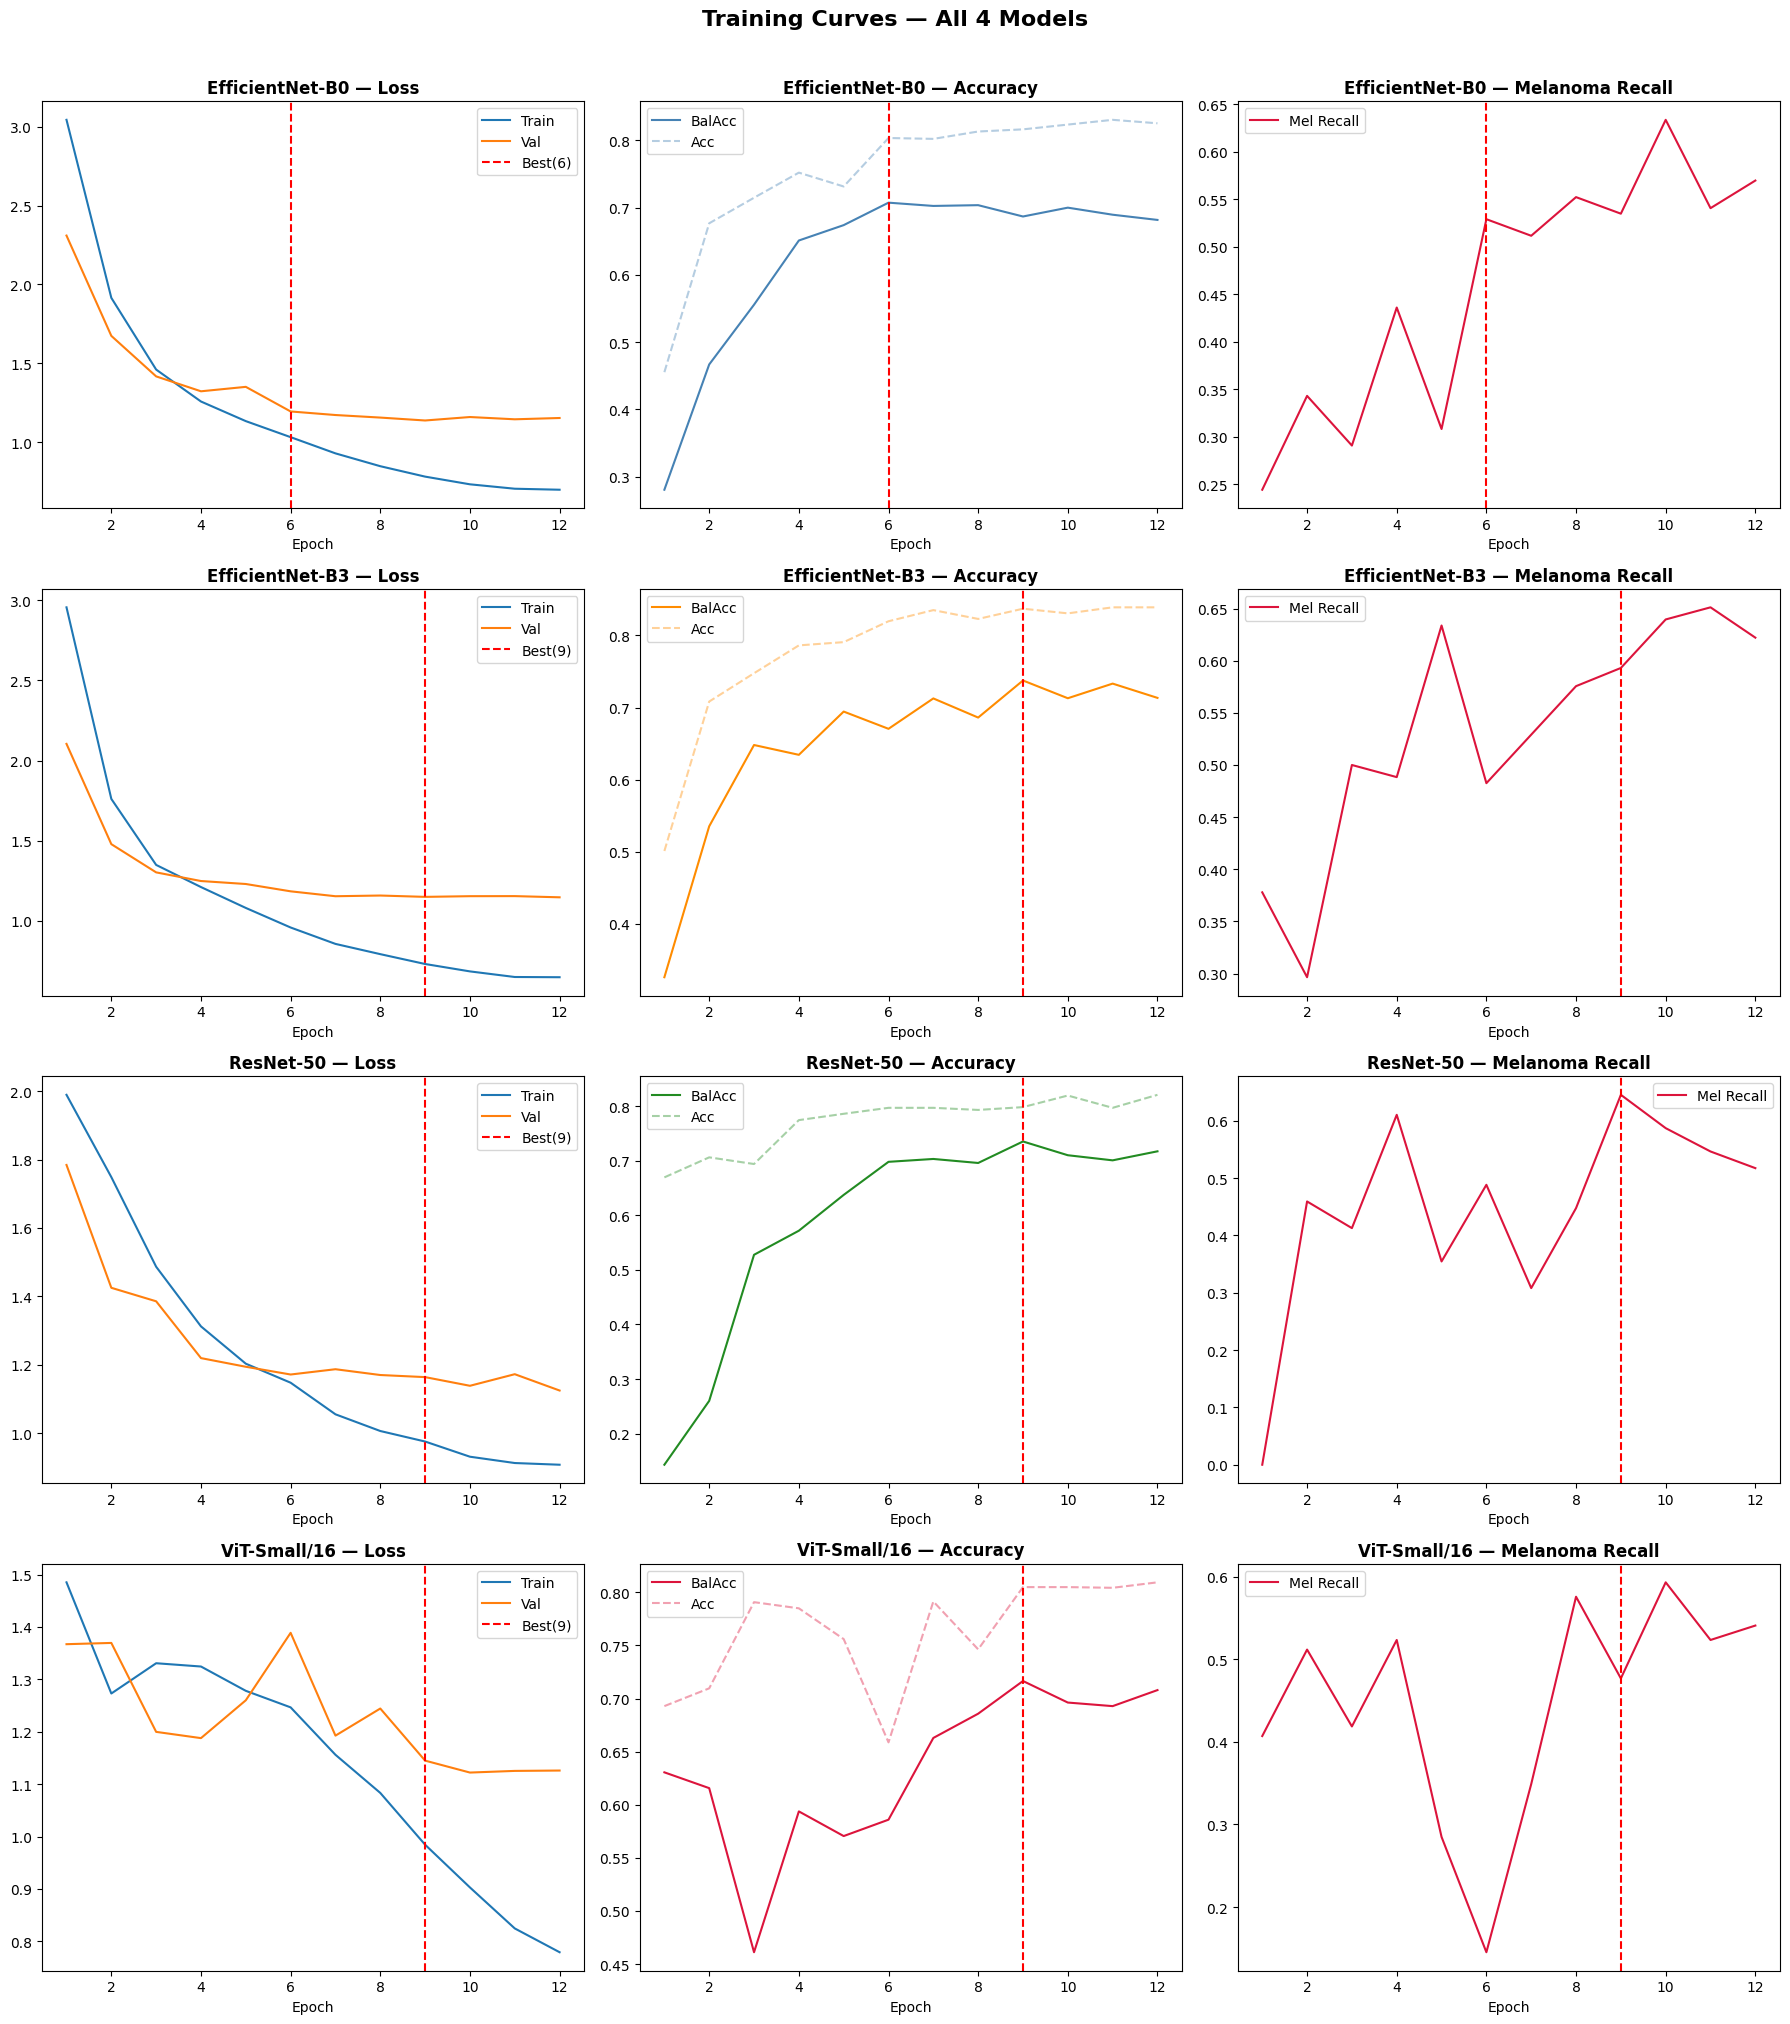

In [22]:
all_runs = [
    ("EfficientNet-B0", efnb0_history, efnb0_best_epoch),
    ("EfficientNet-B3", efnb3_history, efnb3_best_epoch),
    ("ResNet-50",       resnet_history, resnet_best_epoch),
    ("ViT-Small/16",   vit_history,    vit_best_epoch),
]
fig, axes = plt.subplots(len(all_runs), 3, figsize=(18, 5*len(all_runs)))
colors = ["steelblue","darkorange","forestgreen","crimson"]

for row, (name, hist, best_ep) in enumerate(all_runs):
    h = pd.DataFrame(hist)
    ax0, ax1, ax2 = axes[row]
    ax0.plot(h["epoch"], h["tr_loss"],  label="Train"); ax0.plot(h["epoch"], h["val_loss"], label="Val")
    ax0.axvline(best_ep, color="red", ls="--", label=f"Best({best_ep})")
    ax0.set_title(f"{name} — Loss", fontweight="bold"); ax0.legend(); ax0.set_xlabel("Epoch")
    ax1.plot(h["epoch"], h["bal_acc"], color=colors[row], label="BalAcc")
    ax1.plot(h["epoch"], h["acc"],     color=colors[row], alpha=0.4, ls="--", label="Acc")
    ax1.axvline(best_ep, color="red", ls="--")
    ax1.set_title(f"{name} — Accuracy", fontweight="bold"); ax1.legend(); ax1.set_xlabel("Epoch")
    ax2.plot(h["epoch"], h["mel_recall"], color="crimson", label="Mel Recall")
    ax2.axvline(best_ep, color="red", ls="--")
    ax2.set_title(f"{name} — Melanoma Recall", fontweight="bold"); ax2.legend(); ax2.set_xlabel("Epoch")

plt.suptitle("Training Curves — All 4 Models", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("/content/training_curves_all_models.png", dpi=120, bbox_inches="tight")
plt.show()

---
## 14. Individual Model Evaluation (Best Checkpoints)

In [23]:
def evaluate_checkpoint(timm_name, ckpt_name, label):
    """Load best checkpoint and run evaluation on val set."""
    model = timm.create_model(timm_name, pretrained=False, num_classes=NUM_CLASSES).to(DEVICE)
    model.load_state_dict(torch.load(CHECKPOINT_DIR / ckpt_name, map_location=DEVICE))
    model.eval()
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTH)
    _, preds, targets = run_epoch(model, val_loader, criterion)
    m = compute_metrics(preds, targets)
    per_class_recall = recall_score(targets, preds, average=None, zero_division=0)
    print(f"\n{label}")
    print(f"  Accuracy          : {m['acc']:.4f}")
    print(f"  Balanced Accuracy : {m['bal_acc']:.4f}  ← primary metric")
    print(f"  Macro F1          : {m['macro_f1']:.4f}")
    print(f"  Melanoma Recall   : {m['mel_recall']:.4f}  ⚠️ CRITICAL")
    return model, preds, targets, m

efnb0_model, efnb0_preds, val_targets, efnb0_m = evaluate_checkpoint("efficientnet_b0",       "best_efficientnet_b0.pth", "EfficientNet-B0")
efnb3_model, efnb3_preds, _,           efnb3_m = evaluate_checkpoint("efficientnet_b3",       "best_efficientnet_b3.pth", "EfficientNet-B3")
resnet_model, resnet_preds, _,          resnet_m = evaluate_checkpoint("resnet50",              "best_resnet50.pth",          "ResNet-50")
vit_model,   vit_preds,   _,            vit_m    = evaluate_checkpoint("vit_small_patch16_224", "best_vit_small.pth",         "ViT-Small/16")

# ── Per-model summary table ───────────────────────────────────────────────────
print("\n" + "="*65)
print(f"  {'Model':<30} {'BalAcc':>7} {'MacroF1':>8} {'MelRec':>8}")
print("-"*65)
for name, m in [("EfficientNet-B0", efnb0_m), ("EfficientNet-B3", efnb3_m),
                ("ResNet-50",       resnet_m),  ("ViT-Small/16",   vit_m)]:
    print(f"  {name:<30} {m['bal_acc']:>7.4f} {m['macro_f1']:>8.4f} {m['mel_recall']:>8.4f}")
print("="*65)

val:   0%|          | 0/49 [00:00<?, ?it/s]


EfficientNet-B0
  Accuracy          : 0.8036
  Balanced Accuracy : 0.7074  ← primary metric
  Macro F1          : 0.6552
  Melanoma Recall   : 0.5291  ⚠️ CRITICAL


val:   0%|          | 0/49 [00:00<?, ?it/s]


EfficientNet-B3
  Accuracy          : 0.8371
  Balanced Accuracy : 0.7375  ← primary metric
  Macro F1          : 0.7205
  Melanoma Recall   : 0.5930  ⚠️ CRITICAL


val:   0%|          | 0/49 [00:00<?, ?it/s]


ResNet-50
  Accuracy          : 0.7985
  Balanced Accuracy : 0.7355  ← primary metric
  Macro F1          : 0.7097
  Melanoma Recall   : 0.6453  ⚠️ CRITICAL


val:   0%|          | 0/49 [00:00<?, ?it/s]


ViT-Small/16
  Accuracy          : 0.8049
  Balanced Accuracy : 0.7165  ← primary metric
  Macro F1          : 0.6818
  Melanoma Recall   : 0.4767  ⚠️ CRITICAL

  Model                           BalAcc  MacroF1   MelRec
-----------------------------------------------------------------
  EfficientNet-B0                 0.7074   0.6552   0.5291
  EfficientNet-B3                 0.7375   0.7205   0.5930
  ResNet-50                       0.7355   0.7097   0.6453
  ViT-Small/16                    0.7165   0.6818   0.4767


---
## 15. Test-Time Augmentation (TTA) — All 4 Models

In [24]:
def predict_with_tta(model, df, tta_tfms, batch_size=32, device=DEVICE):
    """Returns (averaged_probs [N x C], argmax_preds [N])."""
    model.eval()
    avg_probs = np.zeros((len(df), NUM_CLASSES), dtype=np.float32)
    for t_idx, tfm in enumerate(tta_tfms):
        loader = DataLoader(HAMDataset(df, transform=tfm), batch_size=batch_size,
                            shuffle=False, num_workers=NUM_WORKERS)
        with torch.no_grad():
            probs = np.vstack([F.softmax(model(imgs.to(device)), dim=1).cpu().numpy()
                               for imgs, _ in tqdm(loader, desc=f"TTA {t_idx+1}/{len(tta_tfms)}", leave=False)])
        avg_probs += probs
    avg_probs /= len(tta_tfms)
    return avg_probs, avg_probs.argmax(axis=1)

true_labels = val_df["label"].values

print("Running TTA on all 4 models...")
efnb0_tta_probs, efnb0_tta_preds = predict_with_tta(efnb0_model,  val_df, tta_transforms)
efnb3_tta_probs, efnb3_tta_preds = predict_with_tta(efnb3_model,  val_df, tta_transforms)
resnet_tta_probs, resnet_tta_preds = predict_with_tta(resnet_model, val_df, tta_transforms)
vit_tta_probs,   vit_tta_preds   = predict_with_tta(vit_model,    val_df, tta_transforms)

# TTA metrics per model
print("\n" + "="*65)
print(f"  {'Model':<30} {'BalAcc':>7} {'MacroF1':>8} {'MelRec':>8}")
print("-"*65)
for name, preds in [("EfficientNet-B0 + TTA", efnb0_tta_preds), ("EfficientNet-B3 + TTA", efnb3_tta_preds),
                    ("ResNet-50 + TTA",       resnet_tta_preds),  ("ViT-Small/16 + TTA",   vit_tta_preds)]:
    ba = balanced_accuracy_score(true_labels, preds)
    mf = f1_score(true_labels, preds, average="macro", zero_division=0)
    mr = recall_score(true_labels, preds, labels=[LABEL_MAP["mel"]], average="macro", zero_division=0)
    print(f"  {name:<30} {ba:>7.4f} {mf:>8.4f} {mr:>8.4f}")
print("="*65)

Running TTA on all 4 models...


TTA 1/4:   0%|          | 0/49 [00:00<?, ?it/s]

TTA 2/4:   0%|          | 0/49 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

TTA 3/4:   0%|          | 0/49 [00:00<?, ?it/s]

TTA 4/4:   0%|          | 0/49 [00:00<?, ?it/s]

... (12 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789c5054df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

TTA 3/4:   0%|          | 0/49 [00:00<?, ?it/s]

TTA 4/4:   0%|          | 0/49 [00:00<?, ?it/s]


  Model                           BalAcc  MacroF1   MelRec
-----------------------------------------------------------------
  EfficientNet-B0 + TTA           0.7234   0.6738   0.5349
  EfficientNet-B3 + TTA           0.7303   0.7294   0.6279
  ResNet-50 + TTA                 0.7543   0.7203   0.6453
  ViT-Small/16 + TTA              0.7131   0.6813   0.4942


---
## 16. 4-Model TTA Ensemble

Average softmax probabilities from all 4 models × 4 TTA augmentations = 16 forward passes per image.

In [25]:
# Equal-weight average ensemble
ensemble_probs = (efnb0_tta_probs + efnb3_tta_probs + resnet_tta_probs + vit_tta_probs) / 4.0
ensemble_preds = ensemble_probs.argmax(axis=1)

ens_bal_acc  = balanced_accuracy_score(true_labels, ensemble_preds)
ens_macro_f1 = f1_score(true_labels, ensemble_preds, average="macro", zero_division=0)
ens_mel_rec  = recall_score(true_labels, ensemble_preds, labels=[LABEL_MAP["mel"]], average="macro", zero_division=0)

print("\n" + "="*65)
print(f"  {'Model':<38} {'BalAcc':>7} {'MacroF1':>8} {'MelRec':>7}")
print("-"*65)
for name, preds in [
    ("EfficientNet-B0 + TTA",          efnb0_tta_preds),
    ("EfficientNet-B3 + TTA",          efnb3_tta_preds),
    ("ResNet-50 + TTA",                resnet_tta_preds),
    ("ViT-Small/16 + TTA",             vit_tta_preds),
    ("4-Model Ensemble + TTA",         ensemble_preds),
]:
    ba = balanced_accuracy_score(true_labels, preds)
    mf = f1_score(true_labels, preds, average="macro", zero_division=0)
    mr = recall_score(true_labels, preds, labels=[LABEL_MAP["mel"]], average="macro", zero_division=0)
    sep = "=" if "Ensemble" in name else " "
    print(f"  {name:<38} {ba:>7.4f} {mf:>8.4f} {mr:>7.4f}")
print("="*65)
print(f"\n🏆 Ensemble BalAcc: {ens_bal_acc:.4f} | MacroF1: {ens_macro_f1:.4f} | MelRecall: {ens_mel_rec:.4f}")


  Model                                   BalAcc  MacroF1  MelRec
-----------------------------------------------------------------
  EfficientNet-B0 + TTA                   0.7234   0.6738  0.5349
  EfficientNet-B3 + TTA                   0.7303   0.7294  0.6279
  ResNet-50 + TTA                         0.7543   0.7203  0.6453
  ViT-Small/16 + TTA                      0.7131   0.6813  0.4942
  4-Model Ensemble + TTA                  0.7690   0.7637  0.6453

🏆 Ensemble BalAcc: 0.7690 | MacroF1: 0.7637 | MelRecall: 0.6453


---
## 17. Confusion Matrix — 4-Model Ensemble

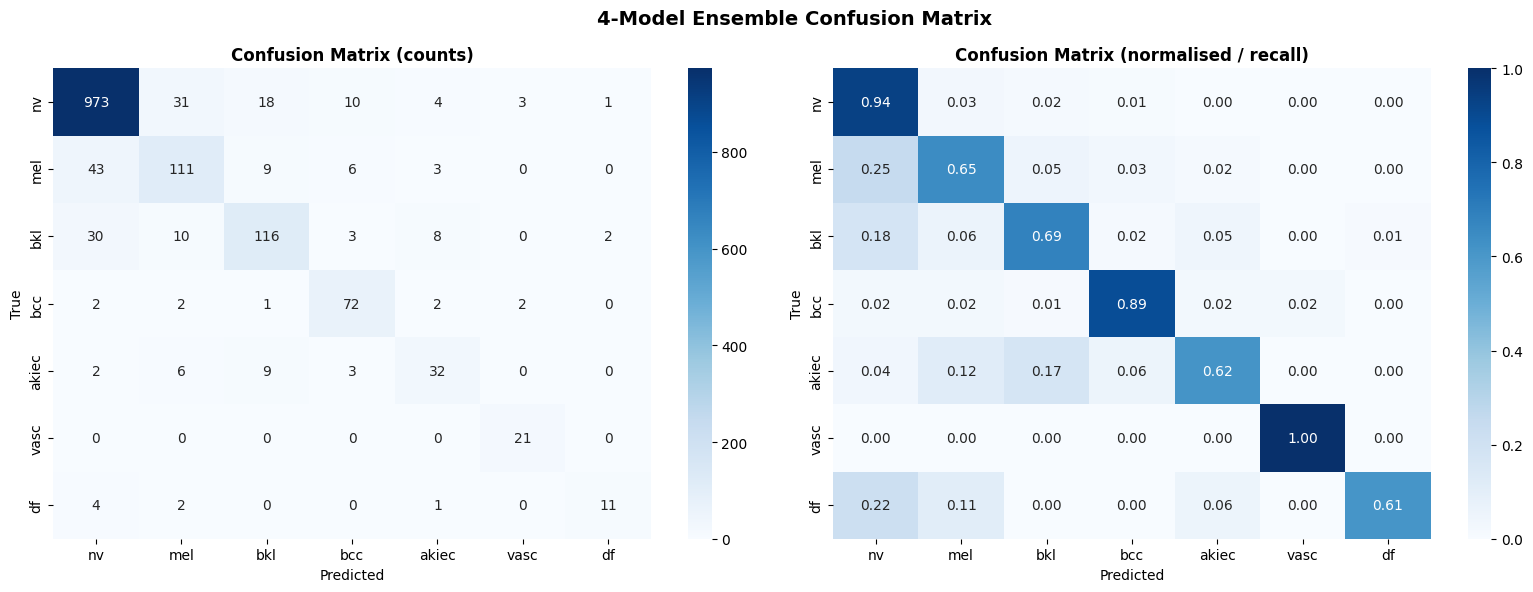


🔴 Melanoma recall: 0.6453  (target: > 0.80)

              precision    recall  f1-score   support

          nv       0.92      0.94      0.93      1040
         mel       0.69      0.65      0.66       172
         bkl       0.76      0.69      0.72       169
         bcc       0.77      0.89      0.82        81
       akiec       0.64      0.62      0.63        52
        vasc       0.81      1.00      0.89        21
          df       0.79      0.61      0.69        18

    accuracy                           0.86      1553
   macro avg       0.77      0.77      0.76      1553
weighted avg       0.86      0.86      0.86      1553



In [26]:
cm      = confusion_matrix(true_labels, ensemble_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(16,6))
for ax, data, fmt, title in zip(axes, [cm, cm_norm], ["d",".2f"],
    ["Confusion Matrix (counts)", "Confusion Matrix (normalised / recall)"]):
    sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(title, fontweight="bold")
plt.suptitle("4-Model Ensemble Confusion Matrix", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("/content/confusion_matrix_ensemble.png", dpi=150)
plt.show()
mel_idx = LABEL_MAP["mel"]
print(f"\n🔴 Melanoma recall: {cm_norm[mel_idx, mel_idx]:.4f}  (target: > 0.80)")
print(f"\n{classification_report(true_labels, ensemble_preds, target_names=CLASS_NAMES, zero_division=0)}")

---
## 18. Temperature Scaling — Confidence Calibration

Calibrate the ensemble probabilities so confidence is trustworthy for the triage engine.

In [30]:
class TemperatureScaler(nn.Module):
    """Post-hoc calibration via single learnable temperature T."""
    def __init__(self, base_model):
        super().__init__()
        self.model = base_model
        self.log_temp = nn.Parameter(torch.zeros(1))  # T = exp(0) = 1.0

    @property
    def temperature(self):
        return torch.exp(self.log_temp).clamp(0.5, 3.0)

    def forward(self, x):
        with torch.no_grad():
            logits = self.model(x)
        return logits / self.temperature

    def calibrate(self, val_loader, device=DEVICE, max_iter=25):
        self.to(device)
        self.model.eval()
        nll = nn.CrossEntropyLoss().to(device)
        opt = torch.optim.LBFGS([self.log_temp], lr=0.01, max_iter=max_iter)
        
        logits_all, labels_all = [], []
        with torch.no_grad():
            for imgs, labels in val_loader:
                logits_all.append(self.model(imgs.to(device)))
                labels_all.append(labels.to(device))
        logits_all = torch.cat(logits_all)
        labels_all = torch.cat(labels_all)

        def eval_step():
            opt.zero_grad()
            loss = nll(logits_all / self.temperature, labels_all)
            loss.backward()
            return loss

        opt.step(eval_step)
        print(f"Calibrated T = {self.temperature.item():.4f}")
        return self


# Calibrate primary model (EfficientNet-B3 — best individual)
scaled_efnb3 = TemperatureScaler(efnb3_model)
scaled_efnb3.calibrate(val_loader, device=DEVICE)
TEMPERATURE = scaled_efnb3.temperature.item()
print(f"Using temperature T = {TEMPERATURE:.4f} for DiagnosisAgent")

Calibrated T = 0.9527
Using temperature T = 0.9527 for DiagnosisAgent


---
## 19. DiagnosisAgent — Inference API

Accepts a raw image path and returns diagnosis with class probabilities. Uses all 4 trained models with TTA + temperature scaling.

In [31]:
class DiagnosisAgent:
    """
    Agent 2 — Diagnosis Agent (4-model ensemble).

    Input  : path to a raw dermoscopic image
    Output : dict with
        predicted_class   : str   e.g. "mel"
        confidence        : float (temperature-scaled, 0-1)
        class_probs       : dict  {class_name: probability}
        melanoma_flag     : bool  True if top-1 is mel OR mel_prob > 0.30
        melanoma_prob     : float
        models_used       : list of model names
    """
    MODEL_SPECS = [
        ("efficientnet_b0",       "best_efficientnet_b0.pth"),
        ("efficientnet_b3",       "best_efficientnet_b3.pth"),
        ("resnet50",              "best_resnet50.pth"),
        ("vit_small_patch16_224", "best_vit_small.pth"),
    ]

    def __init__(self, checkpoint_dir=CHECKPOINT_DIR, temperature=TEMPERATURE, device=DEVICE):
        self.device = device; self.temperature = temperature
        self.models = []
        for timm_name, ckpt_name in self.MODEL_SPECS:
            ckpt_path = checkpoint_dir / ckpt_name
            if ckpt_path.exists():
                m = timm.create_model(timm_name, pretrained=False, num_classes=NUM_CLASSES)
                m.load_state_dict(torch.load(ckpt_path, map_location=device))
                m.to(device).eval()
                self.models.append((timm_name, m))
                print(f"  Loaded: {timm_name}")
            else:
                print(f"  Skipped (no checkpoint): {ckpt_name}")
        print(f"DiagnosisAgent ready with {len(self.models)} model(s).")

    def _preprocess(self, img_path):
        img_np = np.array(Image.open(img_path).convert("RGB"))
        img_np_sog = shades_of_gray(img_np)
        return Image.fromarray(img_np_sog).resize((IMG_SIZE, IMG_SIZE), RESAMPLE)

    def _probs_single(self, model, img_pil):
        """TTA over 4 augmentations, temperature-scaled."""
        avg = np.zeros(NUM_CLASSES, dtype=np.float32)
        with torch.no_grad():
            for tfm in tta_transforms:
                t = tfm(img_pil).unsqueeze(0).to(self.device)
                logits = model(t) / self.temperature
                avg += F.softmax(logits, dim=1).cpu().numpy()[0]
        return avg / len(tta_transforms)

    def predict(self, img_path):
        img_pil = self._preprocess(img_path)
        # Average probs across all loaded models
        all_probs = np.stack([self._probs_single(m, img_pil) for _, m in self.models])
        probs     = all_probs.mean(axis=0)

        top_idx   = int(probs.argmax())
        top_class = IDX_TO_CLASS[top_idx]
        mel_prob  = float(probs[LABEL_MAP["mel"]])

        return {
            "predicted_class": top_class,
            "confidence"     : round(float(probs[top_idx]), 4),
            "class_probs"    : {IDX_TO_CLASS[i]: round(float(p),4) for i,p in enumerate(probs)},
            "melanoma_flag"  : (top_class == "mel") or (mel_prob > 0.30),
            "melanoma_prob"  : round(mel_prob, 4),
            "models_used"    : [name for name,_ in self.models],
        }

# ── Smoke test ───────────────────────────────────────────────────────────────
agent2 = DiagnosisAgent(checkpoint_dir=CHECKPOINT_DIR, temperature=TEMPERATURE)

sample_path = val_df["cache_path"].iloc[0]
result = agent2.predict(sample_path)
print("\nAgent 2 sample output:")
for k, v in result.items(): print(f"  {k:<20}: {v}")
print(f"  {'ground_truth':<20}: {IDX_TO_CLASS[val_df['label'].iloc[0]]}")

  Loaded: efficientnet_b0


  Loaded: efficientnet_b3
  Loaded: resnet50
  Loaded: vit_small_patch16_224
DiagnosisAgent ready with 4 model(s).

Agent 2 sample output:
  predicted_class     : bkl
  confidence          : 0.5394
  class_probs         : {'nv': 0.0078, 'mel': 0.2249, 'bkl': 0.5394, 'bcc': 0.0707, 'akiec': 0.1269, 'vasc': 0.0122, 'df': 0.0181}
  melanoma_flag       : False
  melanoma_prob       : 0.2249
  models_used         : ['efficientnet_b0', 'efficientnet_b3', 'resnet50', 'vit_small_patch16_224']
  ground_truth        : bkl


---
## 20. Save Submission CSV

In [32]:
records = []
for _, row in tqdm(val_df.iterrows(), total=len(val_df), desc="Generating submission"):
    out = agent2.predict(row["cache_path"])
    records.append({
        "image_id"       : row["image_id"],
        "true_label"     : IDX_TO_CLASS[row["label"]],
        "predicted_class": out["predicted_class"],
        "confidence"     : out["confidence"],
        "melanoma_flag"  : out["melanoma_flag"],
        "melanoma_prob"  : out["melanoma_prob"],
        **{f"prob_{cls}": out["class_probs"][cls] for cls in CLASS_NAMES}
    })

sub_df = pd.DataFrame(records)
sub_df.to_csv("/content/agent2_val_predictions.csv", index=False)

final_bal = balanced_accuracy_score(sub_df["true_label"], sub_df["predicted_class"])
final_f1  = f1_score(sub_df["true_label"], sub_df["predicted_class"], average="macro", zero_division=0)
print(f"Saved: /content/agent2_val_predictions.csv  ({len(sub_df)} rows)")
print(f"Final Balanced Accuracy : {final_bal:.4f}")
print(f"Final Macro F1          : {final_f1:.4f}")

Generating submission:   0%|          | 0/1553 [00:00<?, ?it/s]

Saved: /content/agent2_val_predictions.csv  (1553 rows)
Final Balanced Accuracy : 0.7670
Final Macro F1          : 0.7603


---
## 21. Write-Up Notes

### Models & Architecture
All 4 models loaded via `timm` with ImageNet pretrained weights, fully fine-tuned on HAM10000 (no frozen backbone).

| Model | timm name | Checkpoint |
|---|---|---|
| EfficientNet-B0 | efficientnet_b0 | best_efficientnet_b0.pth |
| EfficientNet-B3 | efficientnet_b3 | best_efficientnet_b3.pth |
| ResNet-50 | resnet50 | best_resnet50.pth |
| ViT-Small/16 | vit_small_patch16_224 | best_vit_small.pth |

### Leakage
Split by `lesion_id`. No lesion crosses train/val boundary.

### Imbalance Strategy
Square-root class weights — gentler than inverse-frequency.

### Critical Metric — Melanoma Recall
False-negative melanoma = AUTO_TRIAGE instead of REFER = highest-cost clinical error.

### Ensemble Strategy
Equal-weight average of 4 models × 4 TTA augmentations = 16 forward passes per image.

### Outputs saved to `/content/`
| File | Description |
|---|---|
| checkpoints/best_efficientnet_b0.pth | EfficientNet-B0 weights |
| checkpoints/best_efficientnet_b3.pth | EfficientNet-B3 weights |
| checkpoints/best_resnet50.pth | ResNet-50 weights |
| checkpoints/best_vit_small.pth | ViT-Small/16 weights |
| agent2_val_predictions.csv | Per-image ensemble predictions |
| training_curves_all_models.png | All 4 training curves |
| confusion_matrix_ensemble.png | Ensemble confusion matrix |